Bibliotecas carregadas com sucesso!

DATASET CRIADO:
 agressividade  protecao      perfil
             9         2   agressivo
             8         2   agressivo
            10         1   agressivo
             7         2   agressivo
             9         3   agressivo
             8         4   agressivo
            10         3   agressivo
             7         1   agressivo
             8         1   agressivo
             9         4   agressivo
             7         3   agressivo
            10         2   agressivo
             6         1   agressivo
             8         3   agressivo
             9         1   agressivo
             1         9    protecao
             2         8    protecao
             0        10    protecao
             3         9    protecao
             2         7    protecao
             4         8    protecao
             1         7    protecao
             3        10    protecao
             0         8    protecao
             4        

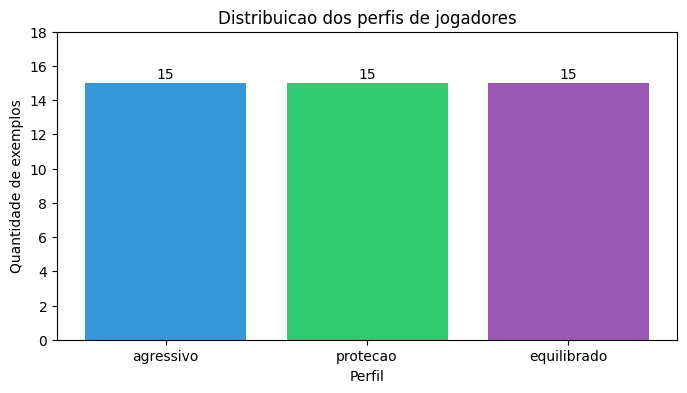


Quantidade de exemplos de treino: 33
Quantidade de exemplos de teste: 12

Modelo treinado com sucesso!

Acuracia do modelo: 83.33%

MATRIZ DE CONFUSAO:
             agressivo  equilibrado  protecao
agressivo            3            1         0
equilibrado          0            3         1
protecao             0            0         4


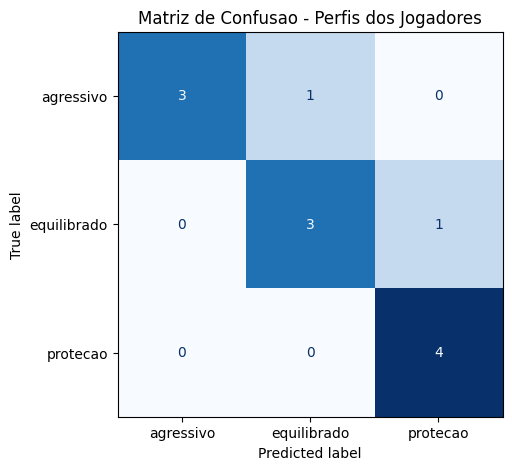


REGRAS APRENDIDAS PELA ARVORE:
|--- protecao <= 6.50
|   |--- agressividade <= 6.50
|   |   |--- class: equilibrado
|   |--- agressividade >  6.50
|   |   |--- protecao <= 4.50
|   |   |   |--- class: agressivo
|   |   |--- protecao >  4.50
|   |   |   |--- class: equilibrado
|--- protecao >  6.50
|   |--- class: protecao



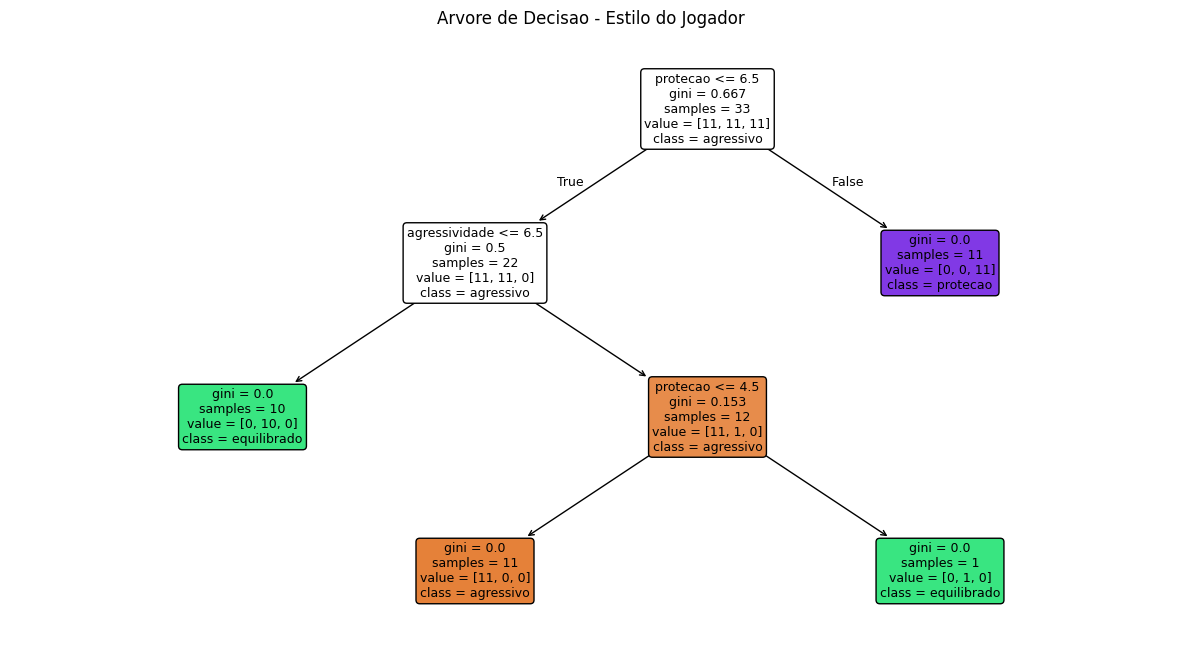


Base de conhecimento carregada!
R1: ['rota_meio', 'dano_magico', 'longo_alcance'] -> Lux
R2: ['rota_topo', 'combate_corpo_a_corpo'] -> Garen
R3: ['rota_atirador', 'dano_fisico', 'longo_alcance'] -> Caitlyn
R4: ['rota_suporte', 'estilo_protecao'] -> Soraka
R5: ['rota_jungle', 'estilo_agressivo', 'dano_magico'] -> Ekko

CASO 1
Perfil previsto: equilibrado
Regra aplicada: R1
Campeao: Lux
Explicacao: Lux utiliza dano magico e consegue atacar inimigos de longa distancia na rota do meio.

CASO 2
Perfil previsto: equilibrado
Regra aplicada: R2
Campeao: Garen
Explicacao: Garen possui habilidades simples de utilizar e funciona bem em confrontos corpo a corpo.

CASO 3
Perfil previsto: equilibrado
Regra aplicada: R3
Campeao: Caitlyn
Explicacao: Caitlyn e uma atiradora de dano fisico que possui grande alcance de ataque.

CASO 4
Perfil previsto: protecao
Regra aplicada: R4
Campeao: Soraka
Explicacao: Soraka consegue curar seus aliados e favorece um estilo voltado para protecao.

CASO 5
Perfil prev

{'regra_aplicada': 'Nenhuma',
 'campeao': 'Sem recomendacao exata',
 'perfil_previsto': 'agressivo',
 'fatos': ['combate_corpo_a_corpo',
  'dano_magico',
  'estilo_agressivo',
  'rota_meio'],
 'explicacao': "Nenhuma regra foi totalmente atendida. A regra mais proxima da rota e R1, mas faltam as condicoes: ['longo_alcance'].",
 'aviso': 'O sistema precisa de mais regras para este caso.'}

In [1]:

# ============================================================
# LOL EXPERT - SISTEMA ESPECIALISTA DE RECOMENDACAO DE CAMPEOES
# Especialista: Ythalo Ornelas
# Experiencia informada: aproximadamente 4.500 horas de jogo
# Disciplina: Inteligencia Artificial, Linguagens Formais e Automatos
# Professora: Kadidja Valeria
# ============================================================

# 1. IMPORTACAO DAS BIBLIOTECAS

import pandas as pd
import matplotlib.pyplot as plt
import unicodedata

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Bibliotecas carregadas com sucesso!")


# ============================================================
# 2. CRIACAO DO DATASET
# ============================================================

# Os exemplos abaixo sao ficticios.
# Foram criados para demonstrar o funcionamento do aprendizado
# supervisionado, e nao representam partidas reais.

# Cada exemplo possui:
# agressividade: nota de 0 a 10
# protecao: interesse em proteger aliados, de 0 a 10
# perfil: rotulo definido para o treinamento

exemplos = {
    "agressivo": [
        (9, 2), (8, 2), (10, 1), (7, 2), (9, 3),
        (8, 4), (10, 3), (7, 1), (8, 1), (9, 4),
        (7, 3), (10, 2), (6, 1), (8, 3), (9, 1)
    ],

    "protecao": [
        (1, 9), (2, 8), (0, 10), (3, 9), (2, 7),
        (4, 8), (1, 7), (3, 10), (0, 8), (4, 9),
        (2, 10), (1, 8), (3, 8), (2, 9), (4, 10)
    ],

    "equilibrado": [
        (4, 4), (5, 5), (6, 5), (4, 6), (5, 4),
        (6, 6), (3, 5), (5, 6), (6, 4), (4, 5),
        (5, 3), (3, 4), (6, 3), (7, 5), (5, 7)
    ]
}

linhas = []

for perfil, valores in exemplos.items():
    for agressividade, protecao in valores:
        linhas.append({
            "agressividade": agressividade,
            "protecao": protecao,
            "perfil": perfil
        })

dados = pd.DataFrame(linhas)

print("\nDATASET CRIADO:")
print(dados.to_string(index=False))

print("\nQuantidade de exemplos:", len(dados))

print("\nDistribuicao dos perfis:")
print(dados["perfil"].value_counts())


# ============================================================
# 3. GRAFICO DA DISTRIBUICAO DOS PERFIS
# ============================================================

contagem = dados["perfil"].value_counts()

plt.figure(figsize=(8, 4))

plt.bar(
    contagem.index,
    contagem.values,
    color=["#3498db", "#2ecc71", "#9b59b6"]
)

plt.title("Distribuicao dos perfis de jogadores")
plt.xlabel("Perfil")
plt.ylabel("Quantidade de exemplos")
plt.ylim(0, 18)

for i, quantidade in enumerate(contagem.values):
    plt.text(i, quantidade + 0.3, str(quantidade), ha="center")

plt.show()


# ============================================================
# 4. SEPARACAO DOS DADOS DE TREINO E TESTE
# ============================================================

# X representa as caracteristicas dos jogadores.
# y representa o perfil que queremos identificar.

X = dados[["agressividade", "protecao"]]
y = dados["perfil"]

# 75% dos dados para treinamento.
# 25% dos dados para teste.

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("\nQuantidade de exemplos de treino:", len(X_treino))
print("Quantidade de exemplos de teste:", len(X_teste))


# ============================================================
# 5. TREINAMENTO DA ARVORE DE DECISAO
# ============================================================

modelo = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

modelo.fit(X_treino, y_treino)

print("\nModelo treinado com sucesso!")

# Testando o aprendizado do modelo.

previsoes = modelo.predict(X_teste)

acuracia = accuracy_score(y_teste, previsoes)

print(f"\nAcuracia do modelo: {acuracia:.2%}")


# ============================================================
# 6. MATRIZ DE CONFUSAO
# ============================================================

classes = sorted(y.unique())

matriz = confusion_matrix(
    y_teste,
    previsoes,
    labels=classes
)

print("\nMATRIZ DE CONFUSAO:")

print(
    pd.DataFrame(
        matriz,
        index=classes,
        columns=classes
    )
)

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=classes
).plot(
    cmap="Blues",
    colorbar=False,
    ax=ax
)

plt.title("Matriz de Confusao - Perfis dos Jogadores")
plt.show()


# ============================================================
# 7. REGRAS APRENDIDAS PELA ARVORE
# ============================================================

print("\nREGRAS APRENDIDAS PELA ARVORE:")

print(
    export_text(
        modelo,
        feature_names=list(X.columns)
    )
)

plt.figure(figsize=(15, 8))

plot_tree(
    modelo,
    feature_names=list(X.columns),
    class_names=list(modelo.classes_),
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Arvore de Decisao - Estilo do Jogador")
plt.show()


# ============================================================
# 8. BASE DE CONHECIMENTO DO SISTEMA ESPECIALISTA
# ============================================================

# Estas regras foram definidas manualmente com base no
# conhecimento do especialista sobre League of Legends.

regras = {
    "R1": {
        "se": [
            "rota_meio",
            "dano_magico",
            "longo_alcance"
        ],
        "entao": "recomendar_lux",
        "campeao": "Lux",
        "explicacao": (
            "Lux utiliza dano magico e consegue atacar "
            "inimigos de longa distancia na rota do meio."
        )
    },

    "R2": {
        "se": [
            "rota_topo",
            "combate_corpo_a_corpo"
        ],
        "entao": "recomendar_garen",
        "campeao": "Garen",
        "explicacao": (
            "Garen possui habilidades simples de utilizar "
            "e funciona bem em confrontos corpo a corpo."
        )
    },

    "R3": {
        "se": [
            "rota_atirador",
            "dano_fisico",
            "longo_alcance"
        ],
        "entao": "recomendar_caitlyn",
        "campeao": "Caitlyn",
        "explicacao": (
            "Caitlyn e uma atiradora de dano fisico "
            "que possui grande alcance de ataque."
        )
    },

    "R4": {
        "se": [
            "rota_suporte",
            "estilo_protecao"
        ],
        "entao": "recomendar_soraka",
        "campeao": "Soraka",
        "explicacao": (
            "Soraka consegue curar seus aliados "
            "e favorece um estilo voltado para protecao."
        )
    },

    "R5": {
        "se": [
            "rota_jungle",
            "estilo_agressivo",
            "dano_magico"
        ],
        "entao": "recomendar_ekko",
        "campeao": "Ekko",
        "explicacao": (
            "Ekko possui dano magico, mobilidade "
            "e possibilidades de realizar jogadas agressivas."
        )
    }
}

print("\nBase de conhecimento carregada!")

for codigo, regra in regras.items():
    print(
        f"{codigo}: {regra['se']} "
        f"-> {regra['campeao']}"
    )


# ============================================================
# 9. NORMALIZACAO DAS RESPOSTAS
# ============================================================

# Permite escrever palavras com acentos ou alguns apelidos.

def limpar_texto(texto):
    texto = str(texto).strip().lower()
    texto = unicodedata.normalize("NFKD", texto)

    return "".join(
        letra for letra in texto
        if not unicodedata.combining(letra)
    )


mapa_rotas = {
    "meio": "meio",
    "mid": "meio",
    "topo": "topo",
    "top": "topo",
    "atirador": "atirador",
    "adc": "atirador",
    "bot": "atirador",
    "suporte": "suporte",
    "sup": "suporte",
    "support": "suporte",
    "selva": "jungle",
    "jungle": "jungle",
    "jg": "jungle"
}

mapa_danos = {
    "magico": "dano_magico",
    "ap": "dano_magico",
    "fisico": "dano_fisico",
    "ad": "dano_fisico",
    "indiferente": "dano_indiferente"
}

mapa_alcances = {
    "longo": "longo_alcance",
    "longo alcance": "longo_alcance",
    "curto": "combate_corpo_a_corpo",
    "corpo a corpo": "combate_corpo_a_corpo",
    "melee": "combate_corpo_a_corpo"
}


# ============================================================
# 10. MOTOR DE INFERENCIA
# ============================================================

def aplicar_regras(fatos):

    for codigo, regra in regras.items():

        # A regra sera aplicada somente quando todas
        # as suas condicoes estiverem presentes.

        if all(
            condicao in fatos
            for condicao in regra["se"]
        ):

            return {
                "regra_aplicada": codigo,
                "campeao": regra["campeao"],
                "acao": regra["entao"],
                "explicacao": regra["explicacao"]
            }

    return None


# ============================================================
# 11. INTEGRACAO DO APRENDIZADO COM O SISTEMA ESPECIALISTA
# ============================================================

def recomendar_campeao(
    rota,
    dano,
    alcance,
    agressividade,
    protecao
):

    rota = mapa_rotas.get(limpar_texto(rota))
    dano = mapa_danos.get(limpar_texto(dano))
    alcance = mapa_alcances.get(limpar_texto(alcance))

    if rota is None:
        raise ValueError("Rota nao reconhecida.")

    if dano is None:
        raise ValueError("Tipo de dano nao reconhecido.")

    if alcance is None:
        raise ValueError("Alcance nao reconhecido.")

    if not 0 <= agressividade <= 10:
        raise ValueError("Agressividade deve estar entre 0 e 10.")

    if not 0 <= protecao <= 10:
        raise ValueError("Protecao deve estar entre 0 e 10.")

    # PRIMEIRA ETAPA:
    # A arvore de decisao identifica o estilo do jogador.

    jogador = pd.DataFrame([{
        "agressividade": agressividade,
        "protecao": protecao
    }])

    perfil_previsto = modelo.predict(jogador)[0]

    # SEGUNDA ETAPA:
    # Os dados e a previsao viram fatos do sistema.

    fatos = {
        f"rota_{rota}",
        dano,
        alcance,
        f"estilo_{perfil_previsto}"
    }

    # TERCEIRA ETAPA:
    # O motor procura uma regra compativel.

    resultado = aplicar_regras(fatos)

    if resultado is not None:

        resultado["perfil_previsto"] = perfil_previsto
        resultado["fatos"] = sorted(fatos)
        resultado["aviso"] = (
            "Recomendacao baseada em regras didaticas. "
            "Nao garante vitorias ou aumento de elo."
        )

        return resultado

    # Caso nenhuma regra seja totalmente atendida,
    # o sistema informa a condicao que esta faltando.

    regras_da_rota = [
        (codigo, regra)
        for codigo, regra in regras.items()
        if f"rota_{rota}" in regra["se"]
    ]

    if regras_da_rota:

        codigo, regra = max(
            regras_da_rota,
            key=lambda item: sum(
                condicao in fatos
                for condicao in item[1]["se"]
            )
        )

        faltando = [
            condicao
            for condicao in regra["se"]
            if condicao not in fatos
        ]

        explicacao = (
            f"Nenhuma regra foi totalmente atendida. "
            f"A regra mais proxima da rota e {codigo}, "
            f"mas faltam as condicoes: {faltando}."
        )

    else:
        explicacao = "Nao existe regra cadastrada para esta rota."

    return {
        "regra_aplicada": "Nenhuma",
        "campeao": "Sem recomendacao exata",
        "perfil_previsto": perfil_previsto,
        "fatos": sorted(fatos),
        "explicacao": explicacao,
        "aviso": "O sistema precisa de mais regras para este caso."
    }


# ============================================================
# 12. TESTANDO CINCO SITUACOES
# ============================================================

casos = [
    ("meio", "magico", "longo", 5, 5),
    ("topo", "fisico", "curto", 4, 5),
    ("atirador", "fisico", "longo", 5, 4),
    ("suporte", "magico", "longo", 2, 9),
    ("jungle", "magico", "curto", 9, 2)
]

for numero, caso in enumerate(casos, start=1):

    resultado = recomendar_campeao(*caso)

    print("\n" + "=" * 45)
    print(f"CASO {numero}")
    print("=" * 45)

    print("Perfil previsto:", resultado["perfil_previsto"])
    print("Regra aplicada:", resultado["regra_aplicada"])
    print("Campeao:", resultado["campeao"])
    print("Explicacao:", resultado["explicacao"])


# ============================================================
# 13. CONSULTA INTERATIVA
# ============================================================

def consulta_interativa():

    print("\n" + "=" * 50)
    print("   BEM-VINDO AO LOL EXPERT")
    print("=" * 50)

    print("\nResponda as perguntas abaixo.")

    rota = input(
        "\nQual rota voce prefere? "
        "(meio, topo, atirador, suporte, jungle): "
    )

    dano = input(
        "Qual tipo de dano prefere? "
        "(magico, fisico, indiferente): "
    )

    alcance = input(
        "Qual distancia de combate prefere? "
        "(longo, curto): "
    )

    agressividade = int(input(
        "Quanto voce gosta de jogar agressivamente? "
        "(0 a 10): "
    ))

    protecao = int(input(
        "Quanto voce gosta de proteger seus aliados? "
        "(0 a 10): "
    ))

    resultado = recomendar_campeao(
        rota,
        dano,
        alcance,
        agressividade,
        protecao
    )

    print("\n" + "=" * 50)
    print("         RESULTADO DO LOL EXPERT")
    print("=" * 50)

    print("\nEstilo identificado:", resultado["perfil_previsto"])
    print("Regra aplicada:", resultado["regra_aplicada"])
    print("Campeao recomendado:", resultado["campeao"])
    print("\nJustificativa:", resultado["explicacao"])
    print("\nObservacao:", resultado["aviso"])

    return resultado


# Para iniciar uma consulta, execute:
consulta_interativa()
